# Estima sensibilidad de entradas basada en varianza

**Pregunta:** ¿Cómo cambia el análisis «Estima sensibilidad de entradas basada en varianza» al ejecutar el mismo mineral de autoría propia con tratamientos controlados?

Nivel: 3. Requisitos previos: Niveles 1 y 2 de este tema y nivel 3 de aprendizaje. Tiempo de lectura: 32 minutos.

## Objetivos

Ejecuta el método de sensibilidad Saltelli-Sobol de producción en un diseño acotado para enseñanza, ordena efectos de primer orden y totales, y explica por qué los índices de muestra pequeña son exploratorios.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Configura las importaciones y registra versiones. Este paso hace reproducible la ejecución del método.

In [1]:
# Importa herramientas de análisis y registra sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resuelve el pipeline local desde la estructura relativa del repositorio.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores de OreFlow; rangos de entrada y salidas definidos en `data/derived/benchmark.json` y `data/derived/contract/operating_contract.json`, licencia MIT del proyecto. Repositorio: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

Para entradas inciertas independientes, los índices Sobol de primer orden miden la varianza explicada por una entrada y los totales incluyen interacciones. SALib construye el diseño Sobol scrambled y estima índices; OreFlow evalúa cada fila con el mismo solver. El diseño didáctico usa una base pequeña para reducir el tiempo de ejecución. No sustituye el registro de sensibilidad de producción ni un análisis empírico de planta.

## Comparación

Saltelli et al. (2010) presentan estimadores de efectos de primer orden y orden total basados en varianza; SALib (Herman y Usher, 2017) aporta el diseño y la implementación de análisis. OreFlow documenta que su bootstrap remuestrea filas de baja discrepancia como si fueran independientes, lo que puede exagerar sus límites de incertidumbre. La corrida pequeña es una demostración reproducible del método, no un estimador novedoso ni una sensibilidad validada en terreno.

Llama el método de sensibilidad de producción OreFlow con un diseño Sobol pequeño y semilla fija para enseñanza.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.methods.uncertainty import sensitivity

# Load this notebook's authored case in its fresh kernel.
case = next(item for item in CASES if item.id == "copper_porphyry_soft")

# Paso ejecutable del método OreFlow explicado en la celda anterior.
indices = sensitivity(case, case.nominal, base_samples=64, seed=20261027)
print(
    "status:",
    indices["status"],
    "| base rows:",
    indices["base_samples"],
    "| engine evaluations:",
    indices["evaluations"],
)
print("inputs and half-widths:", indices["inputs"])


status: computed | base rows: 64 | engine evaluations: 384
inputs and half-widths: {'work_index': {'half_width': 0.2}, 'head_grade': {'half_width': 0.2}, 'liberation_size': {'half_width': 0.25}, 'floatability': {'half_width': 0.25}}


Extrae los índices de primer orden y totales para recuperación. Compara su orden, conservando su incertidumbre muestral.

In [3]:
# Extrae los índices de primer orden y totales para recuperación.
effects = indices["indices"]["recovery_pct"]
if effects.get("constant"):
    print("Recovery is constant at the declared numerical tolerance; no ranking is meaningful.")
else:
    table = pd.DataFrame(
        [
            {
                "input": name,
                "first order": effects["S1"][name],
                "first-order half width": effects["S1_conf"][name],
                "total order": effects["ST"][name],
                "total-order half width": effects["ST_conf"][name],
            }
            for name in indices["inputs"]
        ]
    )
    display(table.sort_values("total order", ascending=False).set_index("input"))


,first order,first-order half width,total order,total-order half width
input,,,,
floatability,0.792495,0.277864,0.799238,0.220069
work_index,0.105186,0.141220,0.140280,0.068846
liberation_size,0.093664,0.090001,0.085582,0.036150
head_grade,0.004543,0.019306,0.003666,0.001483


Grafica los efectos totales con las semiamplitudes bootstrap reportadas. Estimaciones negativas o un total menor al primer orden pueden deberse al error muestral.

Interpretation boundary: simulated response under authored factor ranges; not plant causality.


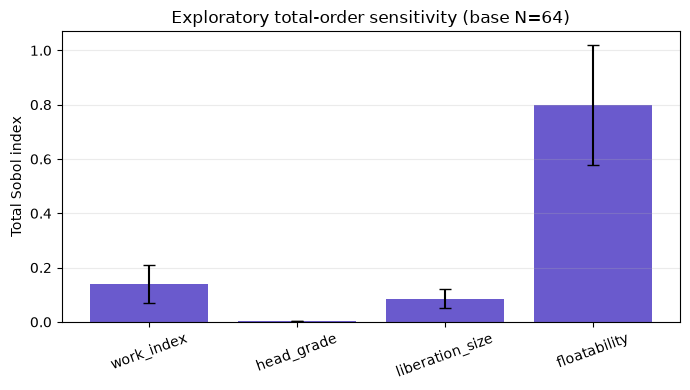

In [4]:
# Grafica los efectos totales con las semiamplitudes bootstrap reportadas.
if not effects.get("constant"):
    names = list(indices["inputs"])
    values = np.asarray([effects["ST"][name] for name in names])
    errors = np.asarray([effects["ST_conf"][name] for name in names])
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(names, values, yerr=errors, capsize=4, color="slateblue")
    ax.set(ylabel="Total Sobol index", title="Exploratory total-order sensitivity (base N=64)")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(True, axis="y", alpha=0.25)
    fig.tight_layout()
print(
    "Interpretation boundary: simulated response under authored factor ranges; not plant causality."
)


Para el caso de nivel 3 sobre 05 uncertainty, solo cambia la alimentación fresca con 0.8 veces el tratamiento nominal. Esta comparación de nivel 3 sobre 05 uncertainty, con 0.8 veces el tratamiento nominal, usa recuperación, P80 y energía para evaluar las restricciones declaradas.

La figura 14 del nivel 3 sobre 05 uncertainty resume circuitos OreFlow resueltos en los ajustes indicados. Su línea guía la comparación, no es una ley de respuesta ajustada ni una banda de confianza. Compara las coordenadas de recuperación y energía con los registros pareados antes de contrastar ajustes candidatos.

In [5]:
# Recalcula el caso de autoría propia con un tratamiento controlado.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_1 = 0.8
point_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_1)
response_1 = simulate(case.ore, case.plant, point_1)
print('tratamiento (t/h):', round(point_1.throughput_tph, 2))
print('recuperación (%):', round(response_1.metrics['recovery_pct'], 3))
print('P80 de producto (µm):', round(response_1.metrics['p80_um'], 2))

tratamiento (t/h): 576.0
recuperación (%): 93.788
P80 de producto (µm): 150.0


Para el caso de nivel 3 sobre 05 uncertainty, solo cambia la alimentación fresca con 0.9 veces el tratamiento nominal. Esta comparación de nivel 3 sobre 05 uncertainty, con 0.9 veces el tratamiento nominal, usa recuperación, P80 y energía para evaluar las restricciones declaradas.

In [6]:
# Recalcula el caso de autoría propia con un tratamiento controlado.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_2 = 0.9
point_2 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_2)
response_2 = simulate(case.ore, case.plant, point_2)
print('tratamiento (t/h):', round(point_2.throughput_tph, 2))
print('recuperación (%):', round(response_2.metrics['recovery_pct'], 3))
print('P80 de producto (µm):', round(response_2.metrics['p80_um'], 2))

tratamiento (t/h): 648.0
recuperación (%): 92.996
P80 de producto (µm): 150.0


Para el caso de nivel 3 sobre 05 uncertainty, solo cambia la alimentación fresca con 1.0 veces el tratamiento nominal. Esta comparación de nivel 3 sobre 05 uncertainty, con 1.0 veces el tratamiento nominal, usa recuperación, P80 y energía para evaluar las restricciones declaradas.

In [7]:
# Recalcula el caso de autoría propia con un tratamiento controlado.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_3 = 1.0
point_3 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_3)
response_3 = simulate(case.ore, case.plant, point_3)
print('tratamiento (t/h):', round(point_3.throughput_tph, 2))
print('recuperación (%):', round(response_3.metrics['recovery_pct'], 3))
print('P80 de producto (µm):', round(response_3.metrics['p80_um'], 2))

tratamiento (t/h): 720.0
recuperación (%): 92.213
P80 de producto (µm): 150.0


Para el caso de nivel 3 sobre 05 uncertainty, solo cambia la alimentación fresca con 1.1 veces el tratamiento nominal. Esta comparación de nivel 3 sobre 05 uncertainty, con 1.1 veces el tratamiento nominal, usa recuperación, P80 y energía para evaluar las restricciones declaradas.

In [8]:
# Recalcula el caso de autoría propia con un tratamiento controlado.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_4 = 1.1
point_4 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_4)
response_4 = simulate(case.ore, case.plant, point_4)
print('tratamiento (t/h):', round(point_4.throughput_tph, 2))
print('recuperación (%):', round(response_4.metrics['recovery_pct'], 3))
print('P80 de producto (µm):', round(response_4.metrics['p80_um'], 2))

tratamiento (t/h): 792.0
recuperación (%): 91.437
P80 de producto (µm): 150.0


Para el caso de nivel 3 sobre 05 uncertainty, solo cambia la alimentación fresca con 1.2 veces el tratamiento nominal. Esta comparación de nivel 3 sobre 05 uncertainty, con 1.2 veces el tratamiento nominal, usa recuperación, P80 y energía para evaluar las restricciones declaradas.

In [9]:
# Recalcula el caso de autoría propia con un tratamiento controlado.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_5 = 1.2
point_5 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_5)
response_5 = simulate(case.ore, case.plant, point_5)
print('tratamiento (t/h):', round(point_5.throughput_tph, 2))
print('recuperación (%):', round(response_5.metrics['recovery_pct'], 3))
print('P80 de producto (µm):', round(response_5.metrics['p80_um'], 2))

tratamiento (t/h): 864.0
recuperación (%): 88.442
P80 de producto (µm): 165.93


En el nivel 3 de 05 uncertainty, los paneles usan los mismos ajustes y 5 puntos resueltos por el modelo, no observaciones de planta. En el nivel 3, la tendencia de 05 uncertainty es la respuesta local de un caso de autoría propia y puede cambiar cerca de límites de potencia o ley; no estima un efecto causal en planta.

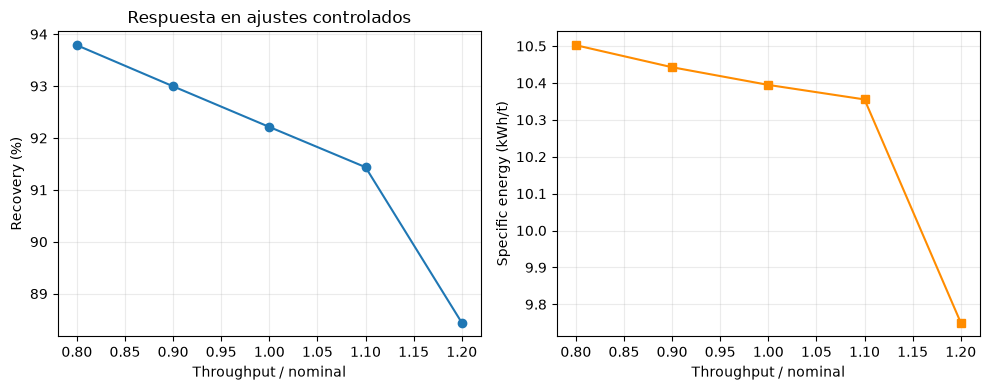

In [10]:
# Compare recovery and specific energy from the executed circuit runs.
import matplotlib.pyplot as plt
factors = [0.8, 0.9, 1.0, 1.1, 1.2]
runs = [response_1, response_2, response_3, response_4, response_5]
recovery = [run.metrics['recovery_pct'] for run in runs]
energy = [run.metrics['specific_energy_total_kwh_t'] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, recovery, marker='o')
axes[0].set(xlabel='Throughput / nominal', ylabel='Recovery (%)', title='Respuesta en ajustes controlados')
axes[1].plot(factors, energy, marker='s', color='darkorange')
axes[1].set(xlabel='Throughput / nominal', ylabel='Specific energy (kWh/t)')
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()

En el análisis de nivel 3 sobre 05 uncertainty, lee esta respuesta de tamaño junto a los paneles de recuperación y energía, no como sustituto. En el nivel 3, un objetivo de molienda constante en este caso de 05 uncertainty puede mantener P80 casi sin cambio mientras potencia, recirculación y residencia alteran otras salidas. Para 05 uncertainty en nivel 3, conserva las alertas del modelo y la auditoría de balance junto con el resultado.

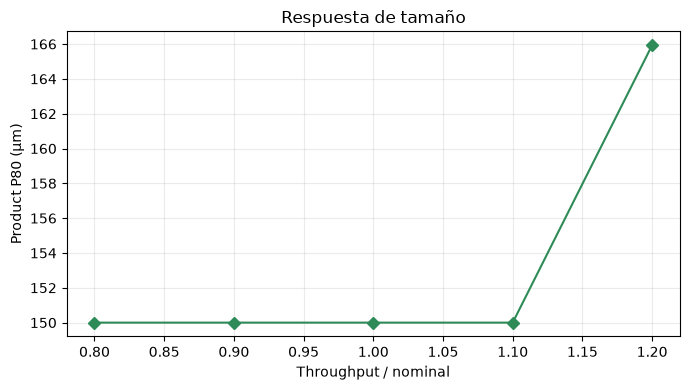

In [11]:
# # Muestra el tamaño de producto aparte: se mide en micrómetros, no en energía o recuperación.
fig, ax = plt.subplots(figsize=(7, 4))
sizes = [run.metrics['p80_um'] for run in runs]
ax.plot(factors, sizes, marker='D', color='seagreen')
ax.set(xlabel='Throughput / nominal', ylabel='Product P80 (µm)', title='Respuesta de tamaño')
ax.grid(True, alpha=0.25)
fig.tight_layout()

En el nivel 3 de 05 uncertainty, la interpretación 1 es que la dispersión de escenarios está condicionada por las distribuciones elegidas, los supuestos de dependencia, el diseño muestral y las ecuaciones de proceso. En el nivel 3 de 05 uncertainty, la interpretación 2 es que la propagación de incertidumbre de OreFlow muestrea factores operativos y minerales acotados, ejecuta el motor exacto del circuito y resume cuantiles de respuesta y probabilidades de restricciones. En el nivel 3 de 05 uncertainty, la interpretación 3 es que una descomposición de Sobol pregunta cómo contribuye la variación de entradas a la varianza de salida bajo sus supuestos de muestreo. En el nivel 3 de 05 uncertainty, la interpretación 4 es que no asigna probabilidades al yacimiento ni establece causalidad. En el nivel 3 de 05 uncertainty, la interpretación 5 es que los índices de primer orden y de orden total responden preguntas distintas porque el orden total incluye interacciones. En el nivel 3 de 05 uncertainty, la interpretación 6 es que las semiamplitudes bootstrap describen estabilidad del estimador para ese diseño, no incertidumbre de la planta real. En el nivel 3 de 05 uncertainty, la interpretación 7 es que informa siempre semilla aleatoria, tamaño de muestra base, límites de entradas, sorteos rechazados y si la salida fue constante dentro de la tolerancia numérica. En el nivel 3 de 05 uncertainty, la interpretación 8 es que sorteos independientes pueden crear combinaciones físicamente improbables cuando variables geológicas covarían, mientras que límites estrechos pueden hacer parecer irrelevante un factor influyente. En el nivel 3 de 05 uncertainty, la interpretación 9 es que separa incertidumbre de entradas de incertidumbre estructural del modelo y error de medición. En el nivel 3 de 05 uncertainty, la interpretación 10 es que para interpretar una decisión, propaga distribuciones calibradas, compara intervalos con campañas de planta reservadas y evalúa si se mantiene el orden de las alternativas operativas. En el nivel 3 de 05 uncertainty, la interpretación 11 es que los escenarios actuales de autoría propia permiten inspeccionar el método y repetirlo. En el nivel 3 de 05 uncertainty, la interpretación 12 es que no entregan un pronóstico probabilístico de una mina o planta.

## Resultados

**Respuesta:** En esta lección de nivel 3 sobre 05 uncertainty, el circuito ejecutado informa una recuperación de 93.788 por ciento para «Estima sensibilidad de entradas basada en varianza» en el primer tratamiento controlado.

Los índices ordenan contribuciones a la varianza bajo factores independientes supuestos y la muestra pequeña elegida. Semiamplitudes amplias o superpuestas indican poca separación. Los índices Sobol describen la estructura de varianza del modelo, no efectos causales observados en planta.

## Resumen

Ejecutaste un método publicado de sensibilidad basada en varianza mediante la implementación OreFlow. Trata el diseño pequeño como experimento didáctico y consulta el análisis mayor comprometido y sus limitaciones bootstrap antes de citar resultados.

## Referencias

- https://doi.org/10.1016/j.cpc.2009.09.018
- https://doi.org/10.21105/joss.00097